# 04 · The model: disposed of within a year?

Logistic regression, linear SVM and random forest against three baselines, on a **time split**:
choose on 2016, refit on 2015–2016, test once on 2017. Numbers come from
`reports/within_1y_results.json` and `reports/experiments.json` (regenerate with the scripts).

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import pandas as pd

from courtcases import plotstyle as ps

ps.apply()
CLEAN, KEYS, FIG = ROOT / "data/clean", ROOT / "data/raw/ddl/keys", ROOT / "reports/figures"
A = json.loads((ROOT / "reports/analysis.json").read_text())
pd.set_option("display.max_colwidth", 70)
R = json.loads((ROOT / "reports/within_1y_results.json").read_text())
E = json.loads((ROOT / "reports/experiments.json").read_text())

## 1. Test year results (2017 filings, never seen during training or model choice)

In [2]:
res = pd.DataFrame(R["test"]).T[["auc", "brier", "log_loss", "accuracy"]]
res.style.format("{:.3f}").highlight_min(subset=["brier", "log_loss"], color="#cde2fb").highlight_max(subset=["auc", "accuracy"], color="#cde2fb")

,auc,brier,log_loss,accuracy
baseline: overall rate,0.500,0.259,0.712,0.505
baseline: rate per case type,0.828,0.163,0.502,0.780
baseline: rate per case type x district,0.844,0.163,0.492,0.759
filing basics | logistic regression (C=0.1),0.842,0.158,0.483,0.780
filing basics | linear SVM (calibrated) (C=0.01),0.843,0.157,0.481,0.782
"filing basics | random forest (min_samples_leaf=300, max_features=sqrt)",0.847,0.159,0.488,0.777
+ law and section | logistic regression (C=1.0),0.873,0.138,0.427,0.809
+ law and section | linear SVM (calibrated) (C=0.01),0.873,0.137,0.429,0.811
"+ law and section | random forest (min_samples_leaf=300, max_features=sqrt)",0.874,0.138,0.428,0.807


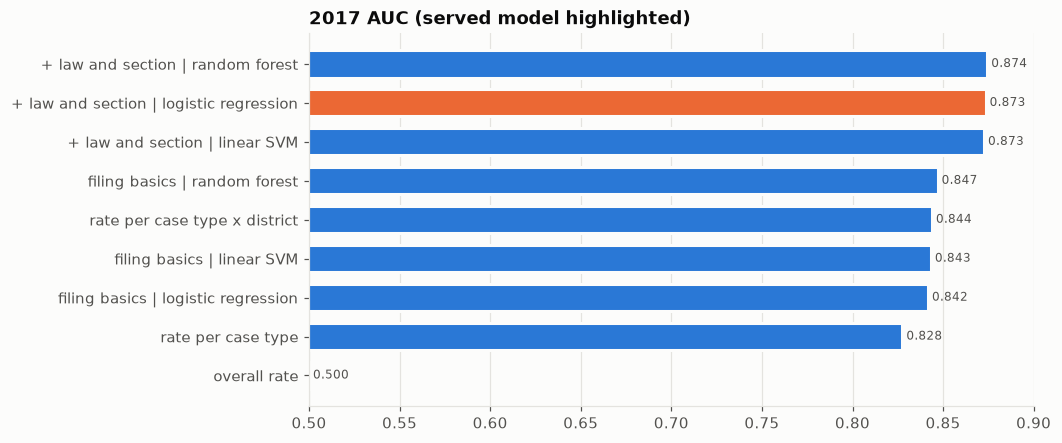

In [3]:
names = list(R["test"]); auc = [R["test"][n]["auc"] for n in names]
short = [n.replace("baseline: ", "").replace(" (calibrated)", "").split(" (")[0] for n in names]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ps.hbar(ax, short, auc, fmt="{:.3f}", highlight={s for s in short if s.startswith("+ law") and "logistic" in s})
ax.set_xlim(0.5, 0.9); ax.set_title("2017 AUC (served model highlighted)")
ps.save(fig, "model_auc", FIG)

## 2. Is a predicted 70% really 70%?

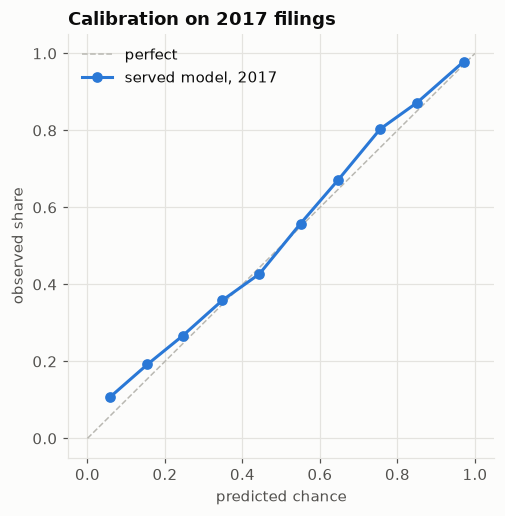

In [4]:
cal = pd.DataFrame(R["served"]["calibration_2017"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color=ps.NEUTRAL, lw=1, ls="--", label="perfect")
ax.plot(cal.mean_predicted, cal.observed, marker="o", color=ps.SERIES[0], label="served model, 2017")
ax.set_xlabel("predicted chance"); ax.set_ylabel("observed share"); ax.legend(loc="upper left")
ax.set_title("Calibration on 2017 filings")
ps.save(fig, "model_calibration", FIG)

## 3. What the model relies on (permutation importance on 2017)

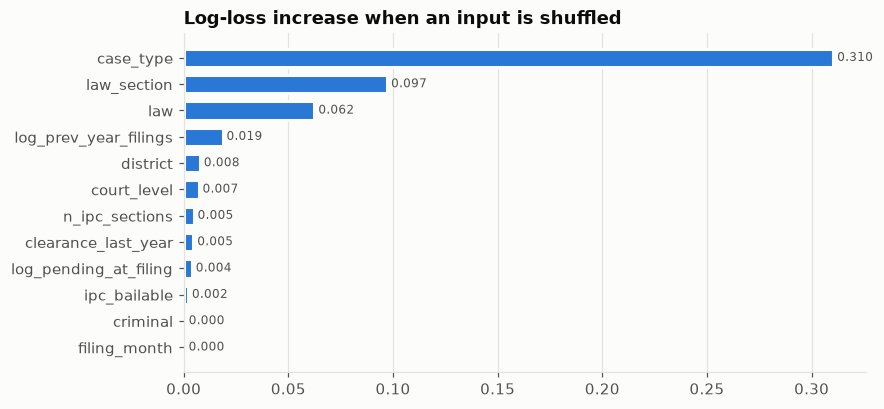

In [5]:
imp = R["served"]["permutation_importance_2017"]
fig, ax = plt.subplots(figsize=(8, 4))
ps.hbar(ax, list(imp), [v["mean"] for v in imp.values()], fmt="{:.3f}")
ax.set_title("Log-loss increase when an input is shuffled"); ps.save(fig, "model_importance", FIG)

## 4. Experiments: drift, horizons, cutoff rule, weak spots

In [6]:
print("Drift (2017):"); display(pd.DataFrame(E["drift"]).T[["auc", "brier", "mean_predicted", "observed"]].round(3))
print("Horizons:"); display(pd.DataFrame({k: {"model AUC": v["model"]["auc"], "per-type AUC": v["baseline: rate per case type"]["auc"],
                                         "test year": v["test"]} for k, v in E["horizons"].items()}).T)
print("Weakest case types (within-type ranking):")
pd.DataFrame(E["weak_spots"]["case_type"])[["case_type", "auc", "n", "mean_predicted", "observed"]].head(8).round(3)

Drift (2017):


,auc,brier,mean_predicted,observed
train 2015-16 (served),0.873,0.138,0.473,0.495
train 2016 only,0.873,0.138,0.482,0.495
"train 2015-16, 2016 weighted 3x",0.874,0.137,0.477,0.495


Horizons:


,model AUC,per-type AUC,test year
180 days,0.917159,0.872191,2017.0
365 days,0.873491,0.827530,2017.0
730 days,0.826065,0.771142,2016.0


Weakest case types (within-type ranking):


,case_type,auc,n,mean_predicted,observed
0,rcop,0.492,3216,0.287,0.331
1,dvc,0.497,3309,0.235,0.207
2,mc,0.556,4898,0.299,0.384
3,prc,0.558,3812,0.299,0.273
4,ep,0.581,35950,0.277,0.317
5,hmop,0.583,15768,0.455,0.506
6,sc,0.592,9220,0.287,0.291
7,os,0.619,86542,0.268,0.310


## Takeaways

- With the law and section, the model beats every baseline on an unseen later year
  (AUC 0.873 vs 0.844 for the case-type × district lookup) and its probabilities are well
  calibrated (Brier 0.138 vs 0.163).
- Most of what it knows is *which kind of case* this is. Within a single civil case type it
  ranks poorly (AUC ~0.5–0.6): it can't tell which original suit will finish early. The site
  says so.
- Courts got faster each year, so 2017 is slightly under-predicted (47% predicted vs 50% observed);
  weighting recent years barely helps. The model describes 2015–2017, not today.